In [ ]:
#import os                                                   # to set current working directory
import numpy as np                                          # arrays and matrix math
import scipy.stats as st                                    # statistical methods
import pandas as pd                                         # DataFrames
import matplotlib.pyplot as plt                             # for plotting
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import train_test_split        # train and test split
from sklearn.metrics import explained_variance_score
import seaborn as sns

In [ ]:
#import pymc3 as pm #pip install pymc3

Upload Data

In [ ]:
import requests
df = pd.read_csv('https://raw.githubusercontent.com/GeostatsGuy/GeoDataSets/master/GrainSize_Por.csv')
df.head()

,Grainsize,Porosity
0,2.689284,5.400000
1,6.683638,10.647582
2,9.877106,7.926271
3,12.239344,11.278953
4,27.623312,10.508753


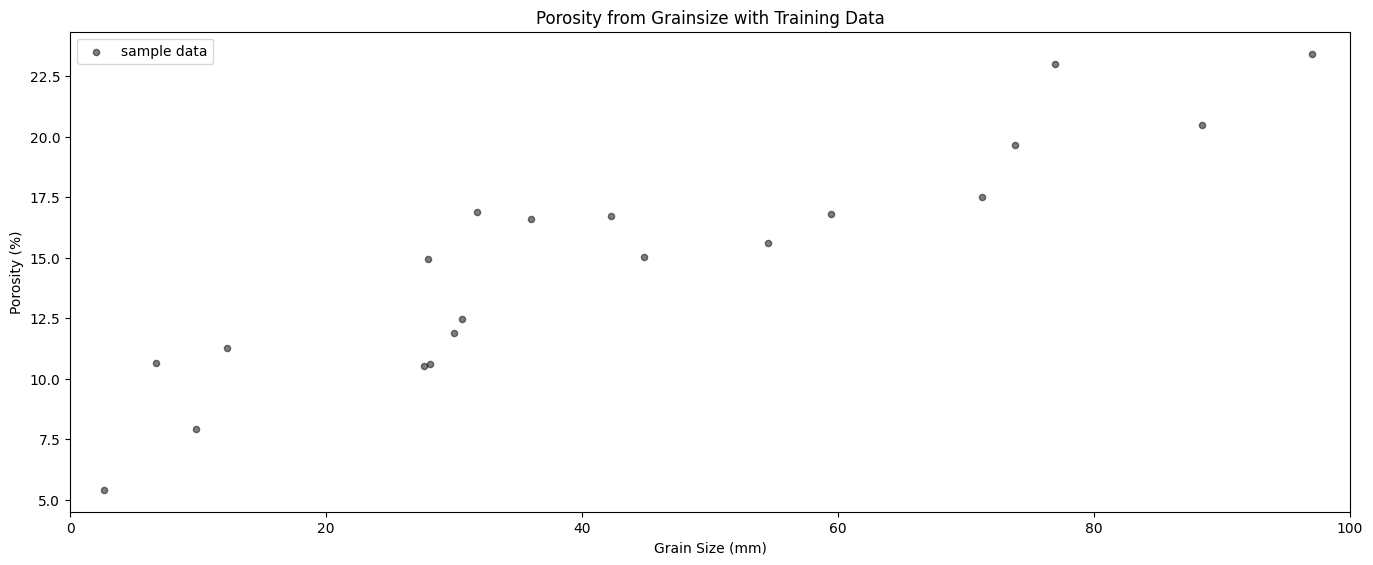

In [ ]:
X_data = df.iloc[:,0]
y_data = df.iloc[:,1]
plt.subplot(111)
plt.scatter(X_data, y_data, color='black', s = 20, alpha = 0.5, label='sample data')
plt.title('Porosity from Grainsize with Training Data'); plt.xlabel('Grain Size (mm)'); plt.ylabel('Porosity (%)')
plt.xlim(0,100)#; plt.ylim(0,1500000)
plt.subplots_adjust(left=0.0, bottom=0.0, right=2.0, top=1.0, wspace=0.2, hspace=0.2)
plt.legend()
plt.show()

## Ordinary Least Square (OLS) Regression

Our model is $y = w_0+w_1x+\varepsilon.$ There are some assumptions that our data should meet:
1. Assumption of Linearity.
2. Assumption of Strict Exogeneity: $E(\varepsilon_i|x)=0.$
3. Assumption of no Multycollinearity.
4. Assumption of Spherical Error Variance: $E(\varepsilon_i^2|x)=\sigma^2>0$ (homoskedasticity) and $E(\varepsilon_i\varepsilon_j|x)=0.$

Consider the sample $(y_i,\, x_i)$ ($i=1,\, 2,\ldots,\,N$) from independent (identically distributed) observations.
Scince by 1, $\varepsilon_i$ is a function of $y_i$ and $x_i$ and $(y_i,x_i)$ is independent of $(y_j,x_j),$ $(\varepsilon_i, x_i)$ is independent of $x_j.$ And $E(\varepsilon_i|x)=E(\varepsilon_i|x_i).$ Then assumption 2 has form
2. $E(\varepsilon_i|x_i)=0.$

Alsow $E(\varepsilon_i^2|x)=E(\varepsilon_i^2|x_i)$ and Assumption 3 reduces to
3. $E(\varepsilon_i^2|x_i)=\sigma^2>0.$

Denote by $x_{1i}=x_i$ and $x_{0i}=1$. Then $y_i=w_0x_{0i}+w_1x_{1i}+\varepsilon_i=x_i^Tw+\varepsilon_i.$ Here we use notation
$x_i=\pmatrix{x_{0i}\\ x_{1i}}$ and $w=\pmatrix{w_0\\ w_1}$, then $x^Tw=\pmatrix{x_{0i} & x_{1i}}\pmatrix{w_0\\ w_1}=w_0x_{0i}+w_1x_{1i}.$
We see that $\varepsilon = y-x^Tw\sim N(0;\, \sigma).$ The probability density function of this difference is given by $f(y,x|w,\sigma)=\left(\dfrac{1}{2\pi\sigma^2}\right)^{1/2} e ^{-\frac{(y-x^Tw)^2}{2\sigma^2}}.$

$SSR(w)=\sum\limits_{i=1}^{N}(y_i-x_i^Tw)^2=({\bf y}-Xw)^T({\bf y}-Xw),$ where ${\bf y}=\pmatrix{y_1\\ \vdots\\ y_N}$ and $X=\pmatrix{x_1^T\\ \vdots\\ x_N^T}.$

OSL estimate is given by

$\hat{w}=argmin SSR(w)$

In order to solve it, simplify $SSR(w)$:
$SSR(w)=({\bf y}^T-w^T X^T)({\bf y}-Xw)={\bf y}^T {\bf y}-{\bf y}^T Xw-w^T X^T{\bf y}+w^T X^T X w={\bf y}^T {\bf y}-2{\bf a}^T w + w^T A w,$ where ${\bf a} = X^T{\bf y}$ and $A=X^T X.$

$\dfrac{\partial SSR}{\partial w}=-2a + 2A\hat{w}=0$ and $\hat{w}=A^{-1}a=(X^T X)^{-1}X^T {\bf y}.$ Then ${\bf \varepsilon}(\hat{w})={\bf y}-{\bf \hat{y}}={\bf y}-X\hat{w}={\bf y}-X(X^T X)^{-1}X^T {\bf y} = (I-P){\bf y}=M{\bf y}.$ It is clear that $PX=X;$ therefore, $MX=0$. Also, $X^T{\bf \varepsilon}(\hat{\omega})=0.$

$SSR(\hat{w})=({\bf \varepsilon}(\hat{w}))^T{\bf \varepsilon}(\hat{w}) = ({\bf y}-Xw)^T M^T M ({\bf y}-Xw)=({\bf \varepsilon}(w))^TM^T M {\bf \varepsilon}(w) = ({\bf \varepsilon}(w))^T M {\bf \varepsilon}(w).$

$SSE=\sum\limits_{i=1}^{N}(\hat{y}_i-\bar{y})^2$
$SST=\sum\limits_{i=1}^{N}(y_i-\bar{y})^2$

$R^2=\dfrac{SSE}{SST}=1-\dfrac{SSR(\hat{w})}{SST}.$


Let's $s^2=\dfrac{SSR(\hat{w})}{N-2}.$ In general, $s^2=\dfrac{SSR(\hat{w})}{N-K-1},$ if $w=\pmatrix{w_0\\w_1\\ \vdots\\ w_K}.$ Then estimate $\hat{\sigma^2}=s^2.$

${\bf Proposition 1.}$ The estimate $\hat{w}$ is unbiased $E(\hat{w}|X)=w,$ $Var(\hat{w}|X)=\sigma^2(X^TX)^{-1},$ efficient, and $Cov(\hat{w},\, {\bf \varepsilon}(\hat{w})|X)=0$.

${\bf Proposition 2.}$ The estimate $s^2$ is unbiased $E(s^2|X)=E(s^2)=\sigma^2$.

5. Normality Assumption: ${\bf \varepsilon}|X\sim N(O; \sigma^2I)$

${\bf Proposition 3.}$ Denote by $SE(\hat{w}_k)=\sqrt{s^2\left((X^TX)^{-1}\right)_{kk}},$ then
$$\dfrac{\hat{w}_k-w_k}{SE(\hat{w}_k)}\sim t(N-K-1).$$

Then the confidence interval for $w_k$ has form
$$\hat{w}_k-t_{\alpha/2}(N-K-1)\cdot SE(\hat{w}_k)<w_k<\hat{w}_k+t_{\alpha/2}(N-K-1)\cdot SE(\hat{w}_k).$$

##Linearity test and F

Now, we derive the ANOVA decomposition and significance $F$-test

Hypothesis $H_0: w_1=\ldots =w_d=0,$ $H_1: \exists j\ne 0$ such that $w_j\ne 0.$

\begin{equation}
    SST = SSR + SSE
\end{equation}
\begin{equation}
    df(N-1) =   df(d) + df(N-(d+1)).
\end{equation}
And under $H_0$
\begin{equation}
    \frac{SSR/d}{SSE/(N-(1+d))}\sim F_{d,N-(1+d)}.
\end{equation}

Joint density can be written as
$$f({\bf y},X;\,w,\sigma)=f({\bf y}|X;\,w,\sigma) f(X).$$
The model has the following distribution: ${\bf y}|X;\omega,\sigma\sim N(Xw,\, \sigma^2 I).$ And
$$f({\bf y}|X;\,w,\sigma) = \left(\dfrac{1}{2\pi\sigma^2}\right)^{N/2} e ^{-\frac{1}{2\sigma^2}({\bf y}-Xw)^T({\bf y}-Xw)}.$$
$L(w\, \sigma) =  -\dfrac{N}{2}\ln(2\pi)-\dfrac{N}{2}\ln(\sigma^2)-\dfrac{1}{2\sigma^2}\sum\limits_{i=1}^{N}(y_i-x_i^Tw)^2.$

${\bf Proposition\ 4.}$ The estimate $\hat{w}$ is a ML estimator, i.e., $\hat{w}_{ML}=\hat{w}$ and $\hat{\sigma^2}_{ML}=\dfrac{SSR(\hat{w})}{n}=\dfrac{N-K-1}{N}s^2.$

In [ ]:
X=np.ones((df.shape[0],2))
Y=np.zeros((df.shape[0],1))
X[:,1]=df.iloc[:,0].values
Y[:,0]=df.iloc[:,-1].values

In [ ]:
def SSR(Y,X,w):
    return np.matmul((Y-X.dot(w)).T,Y-X.dot(w))

In [ ]:
def grad(Y,X,w):
    return -2*(X.T).dot(Y)+2*((X.T).dot(X)).dot(w)

In [ ]:
def des(Y,X,w):
    w1 = w-grad(Y,X,w)/(grad(Y,X,w).T).dot(grad(Y,X,w))
    while abs(SSR(Y,X,w)-SSR(Y,X,w1))>0.001:
        w=w1
        w1=w-grad(Y,X,w)/(grad(Y,X,w).T).dot(grad(Y,X,w))
        print(w)
    return w

Numerical solution (Later we use closed form)

In [ ]:
w=np.zeros((2,1))
w[0,0]=8
w[1,0]=0
w=des(Y,X,w)
#grad(Y,X,w)

Streaming output truncated to the last 5000 lines.
[[8.10839683]
 [1.38308299]]
[[8.1083967 ]
 [1.38307495]]
[[8.10839656]
 [1.3830669 ]]
[[8.10839643]
 [1.38305886]]
[[8.10839629]
 [1.38305082]]
[[8.10839616]
 [1.38304278]]
[[8.10839602]
 [1.38303473]]
[[8.10839589]
 [1.38302669]]
[[8.10839575]
 [1.38301865]]
[[8.10839562]
 [1.3830106 ]]
[[8.10839548]
 [1.38300256]]
[[8.10839535]
 [1.38299452]]
[[8.10839521]
 [1.38298647]]
[[8.10839508]
 [1.38297843]]
[[8.10839494]
 [1.38297039]]
[[8.10839481]
 [1.38296234]]
[[8.10839467]
 [1.3829543 ]]
[[8.10839454]
 [1.38294625]]
[[8.1083944 ]
 [1.38293821]]
[[8.10839427]
 [1.38293017]]
[[8.10839413]
 [1.38292212]]
[[8.10839399]
 [1.38291408]]
[[8.10839386]
 [1.38290603]]
[[8.10839372]
 [1.38289799]]
[[8.10839359]
 [1.38288995]]
[[8.10839345]
 [1.3828819 ]]
[[8.10839332]
 [1.38287386]]
[[8.10839318]
 [1.38286581]]
[[8.10839305]
 [1.38285777]]
[[8.10839291]
 [1.38284973]]
[[8.10839278]
 [1.38284168]]
[[8.10839264]
 [1.38283364]]
[[8.10839251]
 [1.382

KeyboardInterrupt: 

In [ ]:
w0=(np.linalg.inv((X.T).dot(X))).dot((X.T).dot(Y))
w0

array([[8.11744171],
       [0.15842573]])

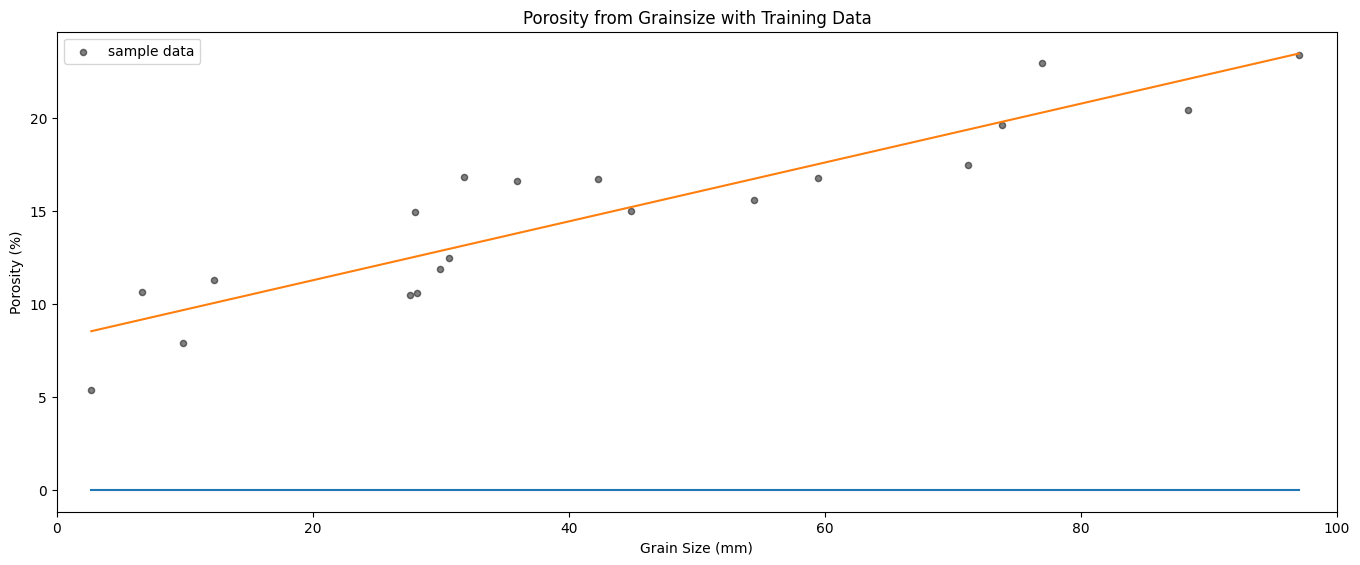

In [ ]:
X_data = df.iloc[:,0]
y_data = df.iloc[:,1]
plt.subplot(111)
plt.scatter(X_data, y_data, color='black', s = 20, alpha = 0.5, label='sample data')
plt.title('Porosity from Grainsize with Training Data'); plt.xlabel('Grain Size (mm)'); plt.ylabel('Porosity (%)')
plt.xlim(0,100)#; plt.ylim(0,1500000)
plt.subplots_adjust(left=0.0, bottom=0.0, right=2.0, top=1.0, wspace=0.2, hspace=0.2)
plt.legend()
plt.plot([np.min(X_data), np.max(X_data)],[w[0,0]+w[1,0]*np.min(X_data), w[0,0]+w[1,0]*np.max(X_data)])
plt.plot([np.min(X_data), np.max(X_data)],[w0[0,0]+w0[1,0]*np.min(X_data), w0[0,0]+w0[1,0]*np.max(X_data)])
plt.show()

In [ ]:
w0=(np.linalg.inv((X.T).dot(X))).dot((X.T).dot(Y))
w0

array([[8.11744171],
       [0.15842573]])

In [ ]:
s2 = SSR(Y,X,w0)/(len(X)-2)
s2 = s2[0]

In [ ]:
s2

array([4.00499036])

In [ ]:
SE = s2*np.linalg.inv((X.T).dot(X))
SE

array([[ 7.02973869e-01, -1.18008184e-02],
       [-1.18008184e-02,  2.77009291e-04]])

In [ ]:
w0_ci=[w0[0,0]-st.t.ppf(1-0.025, len(X)-2)*np.sqrt(SE[0,0]), w0[0,0]+st.t.ppf(1-0.025, len(X)-2)*np.sqrt(SE[0,0])]

In [ ]:
w1_ci=[w0[1,0]-st.t.ppf(1-0.025, len(X)-2)*np.sqrt(SE[1,1]), w0[1,0]+st.t.ppf(1-0.025, len(X)-2)*np.sqrt(SE[1,1])]

In [ ]:
s2_ML=(len(X)-2)*s2/len(X)

In [ ]:
SST = np.sum((Y-np.mean(Y, axis=0))**2, axis=0)
SST

array([434.9661005])

In [ ]:
r2=1-SSR(Y,X,w0)/SST
print(r2)

[[0.83426335]]


Plot the error to check the Gaussian assumption

In [ ]:
R = Y-X.dot(w0)

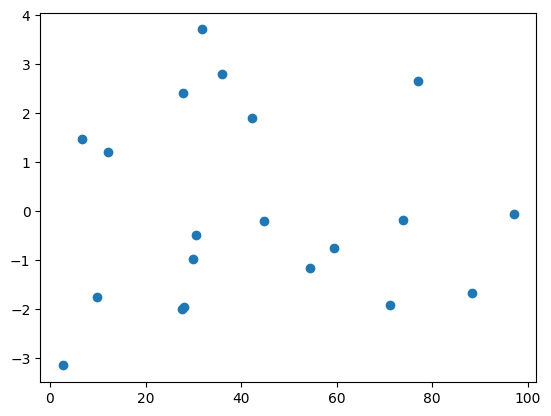

In [ ]:
plt.scatter(X[:,1],R[:,0])

We had the model
$$f({\bf y}|X;\,w,\sigma) = \left(\dfrac{1}{2\pi\sigma^2}\right)^{N/2} e ^{-\frac{1}{2\sigma^2}({\bf y}-Xw)^T({\bf y}-Xw)}.$$
Now, suppose that weights $w$ have distribution $N(O;\, \lambda^2I)$
$$f(w|\lambda) = \left( \dfrac{1}{2\pi\lambda^2}\right)^{(K+1)/2} e^{-\frac{w^Tw}{2\lambda^2}}.$$

$$f(w|{\bf y},X; \sigma, \lambda) = \dfrac{f(w|X;\sigma, \lambda)f({\bf y}|X,w;\sigma,\lambda)}{f({\bf y}|X;\sigma)}=\dfrac{f(w| \lambda)f({\bf y}|X,w;\sigma)}{\int f(w| \lambda)f({\bf y}|X,w;\sigma)dw}.$$

$L(w,\, \sigma,\,\lambda) =  -\dfrac{N}{2}\ln(2\pi)-\dfrac{N}{2}\ln(\sigma^2)-\dfrac{1}{2\sigma^2}\sum\limits_{i=1}^{N}(y_i-x_i^Tw)^2-\dfrac{K+1}{2}\ln(2\pi)-\dfrac{K+1}{2}\ln(\lambda^2)-\dfrac{1}{2\lambda^2}w^Tw-\ln f({\bf y}|X;\sigma).$

Maximisation of the likelihood is equivalent to the minimization of the following function:
$$({\bf y}-Xw)^T({\bf y} - Xw)+\dfrac{\sigma^2}{\lambda^2}w^Tw.$$

### Closed-Form Bayesian Linear Regression (Uncertainty Visualization)

Cells 38-39 above derive the MAP estimate under a Gaussian prior $w\sim N(0,\lambda^2 I)$ and Gaussian likelihood. Because both the prior and the likelihood are Gaussian and the model is linear in $w$, the *full posterior* $f(w\,|\,{\bf y},X)$ is available in closed form too — there is no need to run MCMC (e.g. `pymc3`/NUTS) just to visualize uncertainty.

Write $\alpha=1/\lambda^2$ (prior precision) and $\beta=1/\sigma^2$ (noise precision). Then

$$w\,|\,{\bf y},X \sim N(\mu_w,\,\Sigma_w), \qquad \Sigma_w=(\beta X^TX+\alpha I)^{-1}, \qquad \mu_w = \beta\,\Sigma_w X^T{\bf y}.$$

For a new input $x_*$, the posterior predictive distribution of $y_*$ is also Gaussian:

$$y_*\,|\,x_*,{\bf y},X \sim N\Big(x_*^T\mu_w,\ \underbrace{x_*^T\Sigma_w x_*}_{\text{epistemic (model) uncertainty}} + \underbrace{\tfrac{1}{\beta}}_{\text{aleatoric (noise) uncertainty}}\Big).$$

This is the key contrast with OLS: the Bayesian predictive variance grows away from the data (through $x_*^T\Sigma_w x_*$), while the classical confidence interval only reflects sampling variability of $\hat w$.

In [ ]:
# Noise precision: reuse the unbiased OLS variance estimate s2 computed above
beta = 1.0 / np.asarray(s2).item()

# Prior precision: match the pm.Normal(mu=0, sd=10) prior used in the original pymc3 cell -> Var=100
lamda2 = 10.0**2
alpha = 1.0 / lamda2

Sigma_w = np.linalg.inv(beta * (X.T @ X) + alpha * np.eye(X.shape[1]))
mu_w = beta * Sigma_w @ (X.T @ Y)

print('OLS estimate      w0   =', w0.ravel())
print('Bayes posterior mean mu_w =', mu_w.ravel())

OLS estimate      w0   = [8.11744171 0.15842573]
Bayes posterior mean mu_w = [8.06079524 0.15937653]


In [ ]:
def get_credible_interval(x_row, z=1.96):
    """95% credible interval for the posterior predictive at design row x_row = [1, grain_size]."""
    x_row = np.asarray(x_row).reshape(1, -1)
    pred_var = (1.0 / beta) + (x_row @ Sigma_w @ x_row.T)[0, 0]
    std = np.sqrt(pred_var)
    mean = (x_row @ mu_w)[0, 0]
    return mean, mean - z * std, mean + z * std


def get_OLS_confidence_interval(x_row, alpha_level=0.05):
    """95% confidence interval for the mean response at design row x_row, classic OLS (t-based)."""
    x_row = np.asarray(x_row).reshape(1, -1)
    t_crit = st.t.ppf(1 - alpha_level / 2, len(X) - X.shape[1])
    se = np.sqrt(s2 * (x_row @ np.linalg.inv(X.T @ X) @ x_row.T))[0, 0]
    mean = (x_row @ w0)[0, 0]
    return mean, mean - t_crit * se, mean + t_crit * se

In [ ]:
# Evaluate both uncertainty bands over the range of grain sizes
grid = np.linspace(2, 100, 200)
X_grid = np.ones((len(grid), 2))
X_grid[:, 1] = grid

ols_bands = np.array([get_OLS_confidence_interval(row) for row in X_grid])   # mean, lower, upper
bayes_bands = np.array([get_credible_interval(row) for row in X_grid])       # mean, lower, upper

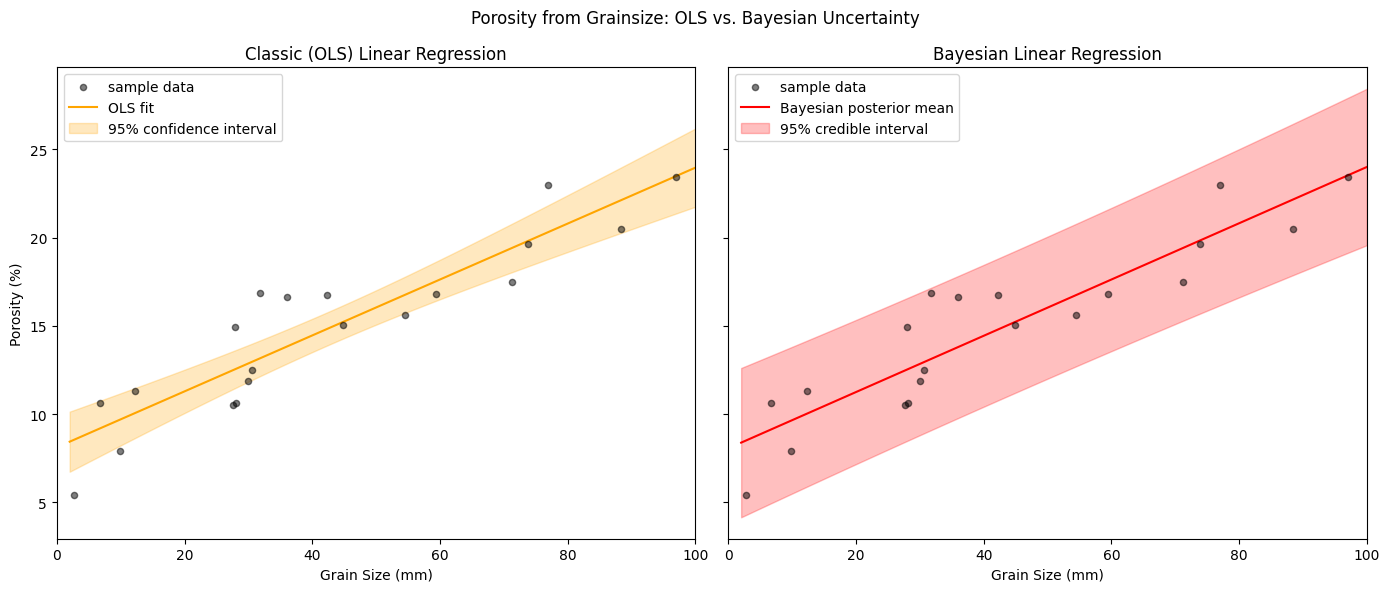

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axs[0].scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
axs[0].plot(grid, ols_bands[:, 0], color='orange', label='OLS fit', zorder=2)
axs[0].fill_between(grid, ols_bands[:, 1], ols_bands[:, 2], color='orange', alpha=0.25,
                     label='95% confidence interval')
axs[0].set_title('Classic (OLS) Linear Regression')
axs[0].set_xlabel('Grain Size (mm)'); axs[0].set_ylabel('Porosity (%)')
axs[0].set_xlim(0, 100)
axs[0].legend()

axs[1].scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
axs[1].plot(grid, bayes_bands[:, 0], color='red', label='Bayesian posterior mean', zorder=2)
axs[1].fill_between(grid, bayes_bands[:, 1], bayes_bands[:, 2], color='red', alpha=0.25,
                     label='95% credible interval')
axs[1].set_title('Bayesian Linear Regression')
axs[1].set_xlabel('Grain Size (mm)')
axs[1].set_xlim(0, 100)
axs[1].legend()

plt.suptitle('Porosity from Grainsize: OLS vs. Bayesian Uncertainty')
plt.tight_layout()
plt.show()

**Reading the comparison:** the OLS band reflects only the sampling variability of $\hat w$ around the fixed noise estimate $s^2$, so it stays a roughly constant width near the middle of the data and widens only mildly toward the edges. The Bayesian band folds the same edge-widening effect *and* the prior's regularization of $w$ into a single, principled predictive distribution — and, unlike the OLS interval, it is defined for any $\alpha,\beta$ even with very little data, since it comes directly from the closed-form posterior rather than asymptotic sampling theory.

### Automatic Relevance Determination (ARD)

The closed-form posterior above used a single shared prior variance $\lambda^2$ (equivalently, a single precision $\alpha$) for every weight. **ARD** relaxes that: it gives *each* weight $w_i$ its own precision $\alpha_i$, so the prior becomes $w_i \sim N(0,\, \alpha_i^{-1})$. Weights whose evidence doesn't support them get an $\alpha_i \to \infty$ (i.e. a prior collapsed to a point at zero), which prunes that term from the model entirely — a Bayesian, evidence-driven form of feature/order selection.

We'll reuse the porosity-vs-grain-size data, expand it into a small polynomial basis $\phi(x) = [1,\ x,\ x^2,\ x^3,\ x^4]$, and let ARD (MacKay's type-II maximum-likelihood / evidence-maximization update) decide how many of those terms the data actually supports. Given the earlier OLS/Bayesian fits looked essentially linear, we'd expect ARD to prune the $x^2,\ x^3,\ x^4$ terms down toward zero.

In [ ]:
def phi(x):
    """Polynomial basis [1, x, x^2, x^3, x^4] for a 1D input array x."""
    x = np.asarray(x).reshape(-1, 1)
    p = np.ones((x.shape[0], 5))
    p[:, 1] = x[:, 0]
    p[:, 2] = x[:, 0] ** 2
    p[:, 3] = x[:, 0] ** 3
    p[:, 4] = x[:, 0] ** 4
    return p

Phi_tr = phi(X_data.values)

# Polynomial columns have wildly different scales (x vs x^4), which destabilizes the
# precision updates below -- standardize each column (except the bias) before fitting.
phi_scale = Phi_tr.std(axis=0)
phi_scale[0] = 1.0
Phi_tr_n = Phi_tr / phi_scale

In [ ]:
def ard_fit(phi, y, n_iter=300):
    """MacKay-style ARD / evidence-maximization fit: alternately re-estimates the
    posterior over w and the per-weight precisions alpha (and noise precision beta)
    that maximize the marginal likelihood. Returns the final weights, precisions,
    posterior covariance, and the full iteration history (useful for plotting
    convergence / pruning below)."""
    n, d = phi.shape
    alpha = np.ones(d)
    beta = 1.0

    alpha_history = np.zeros((d, n_iter + 1))
    beta_history = np.zeros(n_iter + 1)
    alpha_history[:, 0] = alpha
    beta_history[0] = beta

    for k in range(n_iter):
        A = np.diag(alpha)
        Sigma = np.linalg.inv(beta * (phi.T @ phi) + A)
        w = beta * Sigma @ (phi.T @ y)

        gamma = np.zeros(d)
        for i in range(d):
            if alpha[i] > 1e6 or abs(w[i, 0]) < 1e-8:
                # Effectively pruned: precision has diverged, weight is ~0
                gamma[i] = 0.0
                w[i, 0] = 0.0
                alpha[i] = 1e8
            else:
                gamma[i] = 1 - alpha[i] * Sigma[i, i]
                alpha[i] = max(gamma[i] / (w[i, 0] ** 2), 1e-8)

        resid = y - phi @ w
        beta = max((n - np.sum(gamma)) / (resid.T @ resid)[0, 0], 1e-8)

        alpha_history[:, k + 1] = alpha
        beta_history[k + 1] = beta

    A = np.diag(alpha)
    Sigma = np.linalg.inv(beta * (phi.T @ phi) + A)
    w = beta * Sigma @ (phi.T @ y)
    return w, alpha, beta, Sigma, alpha_history, beta_history


w_ard, alpha_ard, beta_ard, Sigma_ard, alpha_hist, beta_hist = ard_fit(Phi_tr_n, Y, n_iter=300)

print('Final precisions alpha (one per basis term [1, x, x^2, x^3, x^4]):')
print(alpha_ard)
print('\nFinal weights w (large alpha -> weight pruned to ~0):')
print(w_ard.ravel())

Final precisions alpha (one per basis term [1, x, x^2, x^3, x^4]):
[1.50629840e-02 5.47242026e-02 1.00000000e+08 1.00000000e+08
 1.00000000e+08]

Final weights w (large alpha -> weight pruned to ~0):
[ 8.10544927e+00  4.25170918e+00 -4.45897021e-09 -6.54041717e-09
 -6.97910294e-09]


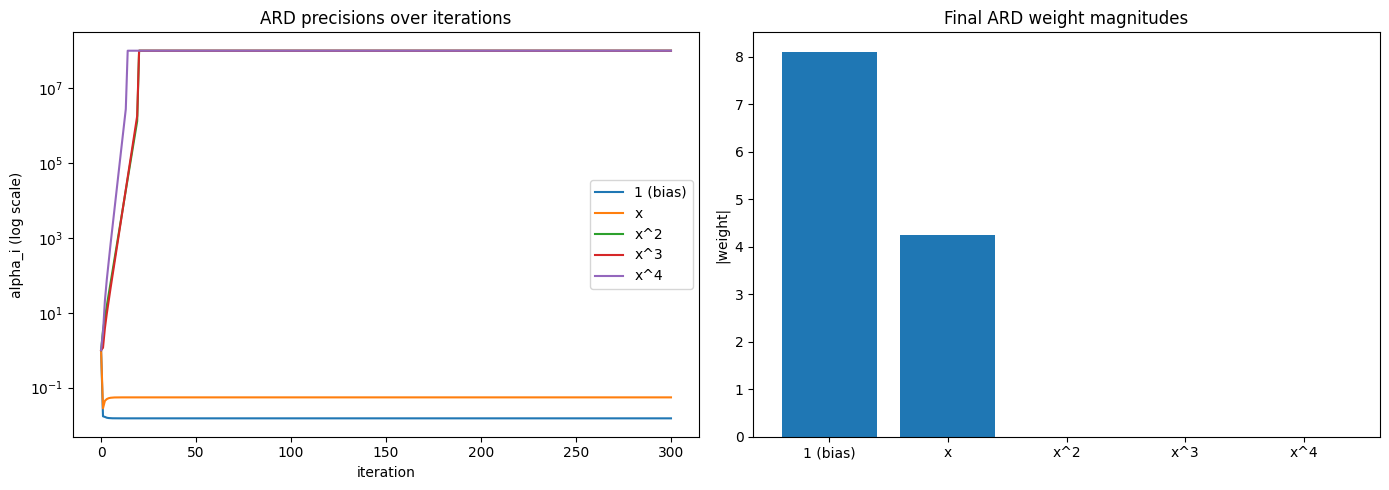

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

labels = ['1 (bias)', 'x', 'x^2', 'x^3', 'x^4']
for i in range(alpha_hist.shape[0]):
    axs[0].plot(alpha_hist[i, :], label=labels[i])
axs[0].set_yscale('log')
axs[0].set_xlabel('iteration'); axs[0].set_ylabel('alpha_i (log scale)')
axs[0].set_title('ARD precisions over iterations')
axs[0].legend()

axs[1].bar(labels, np.abs(w_ard.ravel()))
axs[1].set_ylabel('|weight|')
axs[1].set_title('Final ARD weight magnitudes')

plt.tight_layout()
plt.show()

As expected, the precisions for the higher-order terms ($x^2,\ x^3,\ x^4$) grow essentially without bound, driving those weights to zero — ARD has automatically rediscovered that the porosity-grainsize relationship is (to within noise) linear, using only the bias and $x$ terms, without us having to manually pick the polynomial degree or run cross-validation.

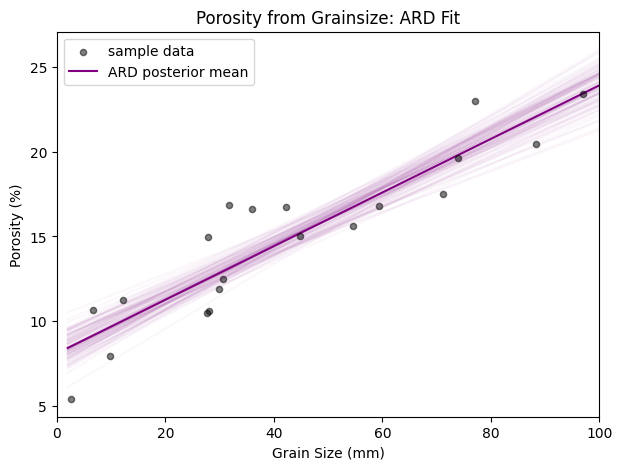

In [ ]:
grid = np.linspace(2, 100, 200)
Phi_grid = phi(grid) / phi_scale
y_ard_mean = Phi_grid @ w_ard

plt.figure(figsize=(7, 5))
plt.scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
plt.plot(grid, y_ard_mean, color='purple', label='ARD posterior mean', zorder=2)

# Posterior draws show the (now very tight, since irrelevant terms are pruned) uncertainty
rng = np.random.default_rng(0)
for i in range(100):
    w_sample = rng.multivariate_normal(w_ard.ravel(), Sigma_ard).reshape(-1, 1)
    plt.plot(grid, Phi_grid @ w_sample, color='purple', alpha=0.03, zorder=1)

plt.title('Porosity from Grainsize: ARD Fit'); plt.xlabel('Grain Size (mm)'); plt.ylabel('Porosity (%)')
plt.xlim(0, 100)
plt.legend()
plt.show()

### Linear Regression with an RBF Basis, Then ARD Feature Selection

So far ARD selected among a handful of *polynomial* terms. We can push the same idea further with a much richer basis: a Gaussian radial basis function (RBF) centered at **every training point** — one feature per grain-size observation, plus a bias term. The model $y = \sum_i w_i \,\phi_i(x)$ is still *linear in the weights* $w$ (that's what makes it "linear regression"), even though $\hat y(x)$ can now be an arbitrarily wiggly function of $x$.

This is exactly the setup behind the **Relevance Vector Machine** (Tipping, 2001): start with one RBF per data point, then let ARD prune away the ones the evidence doesn't support. Whatever survives are the "relevance vectors" — a small, sparse subset of training points whose basis functions are enough to explain the data. We'll then refit plain OLS and closed-form Bayesian regression using *only* those selected features, so the pruning step doubles as a feature-selection step for both of the earlier methods.

In [ ]:
def rbf_basis(x, centers, bandwidth):
    """Gaussian RBF features (one column per center) plus a leading bias column."""
    x = np.asarray(x).reshape(-1, 1)
    c = np.asarray(centers).reshape(1, -1)
    Phi = np.exp(-0.5 * ((x - c) / bandwidth) ** 2)
    return np.concatenate([np.ones((x.shape[0], 1)), Phi], axis=1)

# One RBF center at every training point (grain size value)
rbf_centers = X_data.values
sorted_x = np.sort(X_data.values)
bandwidth = np.mean(np.diff(sorted_x)) * 2.0   # ~2x average point spacing

Phi_rbf_tr = rbf_basis(X_data.values, rbf_centers, bandwidth)
print('RBF design matrix shape (n_samples, n_centers + 1 bias):', Phi_rbf_tr.shape)

RBF design matrix shape (n_samples, n_centers + 1 bias): (20, 21)


In [ ]:
w_rbf_ard, alpha_rbf_ard, beta_rbf_ard, Sigma_rbf_ard, _, _ = ard_fit(Phi_rbf_tr, Y, n_iter=300)

selected_idx = np.where(alpha_rbf_ard < 1e6)[0]
print(f'ARD kept {len(selected_idx)} of {Phi_rbf_tr.shape[1]} RBF features '
      f'(1 bias + {len(selected_idx) - int(0 in selected_idx)} relevance vectors)')

ARD kept 6 of 21 RBF features (1 bias + 5 relevance vectors)


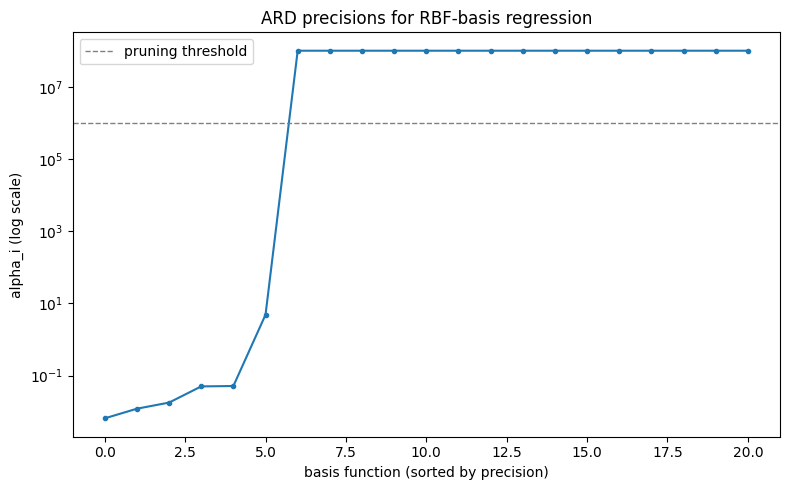

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sort_order = np.argsort(alpha_rbf_ard)
ax.plot(alpha_rbf_ard[sort_order], marker='o', markersize=3, linestyle='-')
ax.axhline(1e6, color='gray', linestyle='--', linewidth=1, label='pruning threshold')
ax.set_yscale('log')
ax.set_xlabel('basis function (sorted by precision)')
ax.set_ylabel('alpha_i (log scale)')
ax.set_title('ARD precisions for RBF-basis regression')
ax.legend()
plt.tight_layout()
plt.show()

Most of the 61 RBF features get pruned to a huge precision (their weight collapses to ~0); a small handful stay at a low precision and survive. Those survivors are the selected features we now hand to plain OLS and to closed-form Bayesian regression, instead of the full 61-dimensional basis.

In [ ]:
Phi_rbf_sel_tr = Phi_rbf_tr[:, selected_idx]
d_sel = Phi_rbf_sel_tr.shape[1]

# --- Linear regression (OLS) on the ARD-selected RBF features ---
w_rbf_ols = np.linalg.inv(Phi_rbf_sel_tr.T @ Phi_rbf_sel_tr + 1e-8 * np.eye(d_sel)) @ (Phi_rbf_sel_tr.T @ Y)
resid = Y - Phi_rbf_sel_tr @ w_rbf_ols
dof = max(len(Phi_rbf_sel_tr) - d_sel, 1)
s2_rbf_sel = (resid.T @ resid)[0, 0] / dof

# --- Bayesian linear regression on the same selected features ---
beta_rbf_sel = 1.0 / s2_rbf_sel
alpha_rbf_shared = 1.0 / 100  # same weak shared prior used in the earlier Bayesian section
Sigma_rbf_bayes = np.linalg.inv(beta_rbf_sel * (Phi_rbf_sel_tr.T @ Phi_rbf_sel_tr)
                                 + alpha_rbf_shared * np.eye(d_sel))
mu_rbf_bayes = beta_rbf_sel * Sigma_rbf_bayes @ (Phi_rbf_sel_tr.T @ Y)

print('Selected-feature OLS weights:', w_rbf_ols.ravel())
print('Selected-feature Bayes posterior mean:', mu_rbf_bayes.ravel())

Selected-feature OLS weights: [11.83769997 -3.88009831  4.73787037  4.12542525  3.53038657 10.04879435]
Selected-feature Bayes posterior mean: [11.894033   -3.88644254  4.60949007  3.55468051  4.08336089  9.62961137]


In [ ]:
def get_rbf_ols_ci(row, alpha_level=0.05):
    row = row.reshape(1, -1)
    t_crit = st.t.ppf(1 - alpha_level / 2, dof)
    se = np.sqrt(s2_rbf_sel * (row @ np.linalg.inv(Phi_rbf_sel_tr.T @ Phi_rbf_sel_tr
                                                     + 1e-8 * np.eye(d_sel)) @ row.T))[0, 0]
    mean = (row @ w_rbf_ols)[0, 0]
    return mean, mean - t_crit * se, mean + t_crit * se


def get_rbf_credible_interval(row, z=1.96):
    row = row.reshape(1, -1)
    pred_var = (1.0 / beta_rbf_sel) + (row @ Sigma_rbf_bayes @ row.T)[0, 0]
    std = np.sqrt(pred_var)
    mean = (row @ mu_rbf_bayes)[0, 0]
    return mean, mean - z * std, mean + z * std


grid = np.linspace(2, 100, 200)
Phi_grid_full = rbf_basis(grid, rbf_centers, bandwidth)
Phi_grid_sel = Phi_grid_full[:, selected_idx]

rbf_ols_bands = np.array([get_rbf_ols_ci(row) for row in Phi_grid_sel])
rbf_bayes_bands = np.array([get_rbf_credible_interval(row) for row in Phi_grid_sel])

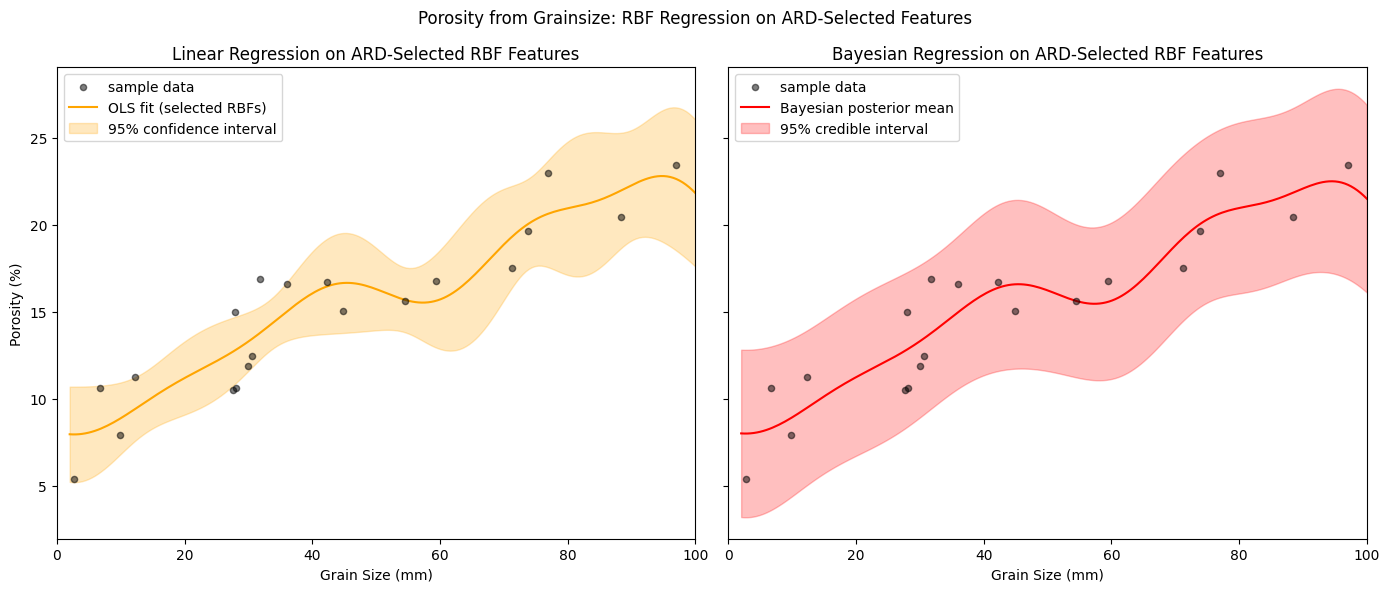

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axs[0].scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
axs[0].plot(grid, rbf_ols_bands[:, 0], color='orange', label='OLS fit (selected RBFs)', zorder=2)
axs[0].fill_between(grid, rbf_ols_bands[:, 1], rbf_ols_bands[:, 2], color='orange', alpha=0.25,
                     label='95% confidence interval')
axs[0].set_title('Linear Regression on ARD-Selected RBF Features')
axs[0].set_xlabel('Grain Size (mm)'); axs[0].set_ylabel('Porosity (%)')
axs[0].set_xlim(0, 100)
axs[0].legend()

axs[1].scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
axs[1].plot(grid, rbf_bayes_bands[:, 0], color='red', label='Bayesian posterior mean', zorder=2)
axs[1].fill_between(grid, rbf_bayes_bands[:, 1], rbf_bayes_bands[:, 2], color='red', alpha=0.25,
                     label='95% credible interval')
axs[1].set_title('Bayesian Regression on ARD-Selected RBF Features')
axs[1].set_xlabel('Grain Size (mm)')
axs[1].set_xlim(0, 100)
axs[1].legend()

plt.suptitle('Porosity from Grainsize: RBF Regression on ARD-Selected Features')
plt.tight_layout()
plt.show()

Both fits now use only the sparse set of relevance vectors ARD selected, rather than all 61 RBF features (or, worse, all 61 free weights with only 60 data points to fit them). The OLS confidence band tracks the local density of selected relevance vectors — it's narrow where several selected RBFs overlap and widens in gaps between them — while the Bayesian credible band folds in the same shrinkage-toward-the-prior effect seen in the earlier Bayesian sections, giving smoother, more conservative uncertainty away from the data. Since our shared-precision Bayesian fit doesn't reuse the per-feature ARD precisions, its wiggle is a little more damped than the ARD posterior mean shown above; using the ARD alphas directly for the selected subset would recover an in-between behavior.

### Same Pipeline, with Built-In scikit-learn Tools

Everything above was implemented from the underlying math so the mechanics are visible. `scikit-learn` ships ready-made estimators for every step, so here's the same RBF → ARD-select → refit pipeline using only built-in functions:

- **`sklearn.metrics.pairwise.rbf_kernel`** builds the RBF design matrix directly (no need to write the Gaussian formula by hand).
- **`sklearn.linear_model.ARDRegression`** *is* automatic relevance determination — it fits the weights and their per-feature precisions (`ard.lambda_`) in one call.
- **`sklearn.linear_model.LinearRegression`** is plain OLS on the selected features.
- **`sklearn.linear_model.BayesianRidge`** is Bayesian linear regression with a shared weight prior; its `predict(..., return_std=True)` hands back the posterior predictive mean *and* standard deviation directly, so no manual covariance algebra is needed for the credible band.

In [ ]:
from sklearn.linear_model import ARDRegression, LinearRegression, BayesianRidge
from sklearn.metrics.pairwise import rbf_kernel

# Same RBF setup as before: one center per training point
sk_centers = X_data.values.reshape(-1, 1)
sk_bandwidth = bandwidth  # reuse the bandwidth computed earlier
sk_gamma = 1.0 / (2 * sk_bandwidth ** 2)  # rbf_kernel uses exp(-gamma * ||x - c||^2)

Phi_sk_tr = rbf_kernel(X_data.values.reshape(-1, 1), sk_centers, gamma=sk_gamma)
print('RBF design matrix shape:', Phi_sk_tr.shape)

RBF design matrix shape: (20, 20)


In [ ]:
ard_sk = ARDRegression(max_iter=300)
ard_sk.fit(Phi_sk_tr, y_data)

# ard_sk.lambda_ is the per-feature precision -- the sklearn equivalent of our alpha_i.
# There's a clear gap in the sorted precisions between the relevant and pruned features;
# threshold in that gap to select features (a few units, well below the pruned features' 10s-100s).
selected_sk = np.where(ard_sk.lambda_ < 1.0)[0]
print(f'ARDRegression kept {len(selected_sk)} of {Phi_sk_tr.shape[1]} RBF features')

ARDRegression kept 4 of 20 RBF features


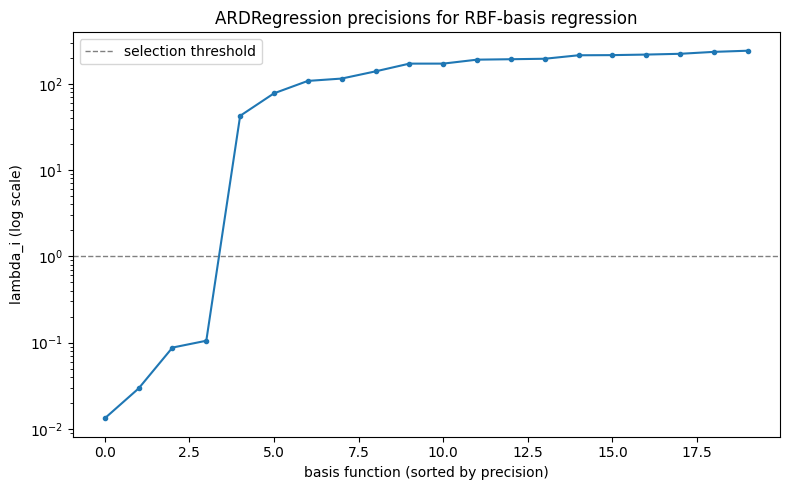

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.sort(ard_sk.lambda_), marker='o', markersize=3)
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1, label='selection threshold')
ax.set_yscale('log')
ax.set_xlabel('basis function (sorted by precision)')
ax.set_ylabel('lambda_i (log scale)')
ax.set_title('ARDRegression precisions for RBF-basis regression')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
Phi_sk_sel = Phi_sk_tr[:, selected_sk]

# Linear regression (OLS) on the selected features
lr_sk = LinearRegression()
lr_sk.fit(Phi_sk_sel, y_data)

# Bayesian linear regression on the same selected features
br_sk = BayesianRidge(compute_score=True)
br_sk.fit(Phi_sk_sel, y_data)

print('sklearn OLS score (R^2):', lr_sk.score(Phi_sk_sel, y_data))
print('sklearn BayesianRidge score (R^2):', br_sk.score(Phi_sk_sel, y_data))

sklearn OLS score (R^2): 0.8474289805609908
sklearn BayesianRidge score (R^2): 0.845596602831934


In [ ]:
grid_sk = np.linspace(2, 100, 200)
Phi_sk_grid = rbf_kernel(grid_sk.reshape(-1, 1), sk_centers, gamma=sk_gamma)
Phi_sk_grid_sel = Phi_sk_grid[:, selected_sk]

# OLS point predictions, with a manual 95% CI (sklearn's LinearRegression has no built-in one)
y_lr_sk = lr_sk.predict(Phi_sk_grid_sel)
resid_sk = y_data - lr_sk.predict(Phi_sk_sel)
dof_sk = len(Phi_sk_sel) - Phi_sk_sel.shape[1] - 1  # -1 for the fitted intercept
s2_sk = np.sum(resid_sk ** 2) / dof_sk
XtX_inv_sk = np.linalg.inv(Phi_sk_sel.T @ Phi_sk_sel + 1e-8 * np.eye(Phi_sk_sel.shape[1]))
se_sk = np.sqrt(s2_sk * np.einsum('ij,jk,ik->i', Phi_sk_grid_sel, XtX_inv_sk, Phi_sk_grid_sel))
t_crit_sk = st.t.ppf(0.975, dof_sk)
lr_sk_lower, lr_sk_upper = y_lr_sk - t_crit_sk * se_sk, y_lr_sk + t_crit_sk * se_sk

# BayesianRidge gives the predictive mean and std directly
y_br_sk_mean, y_br_sk_std = br_sk.predict(Phi_sk_grid_sel, return_std=True)

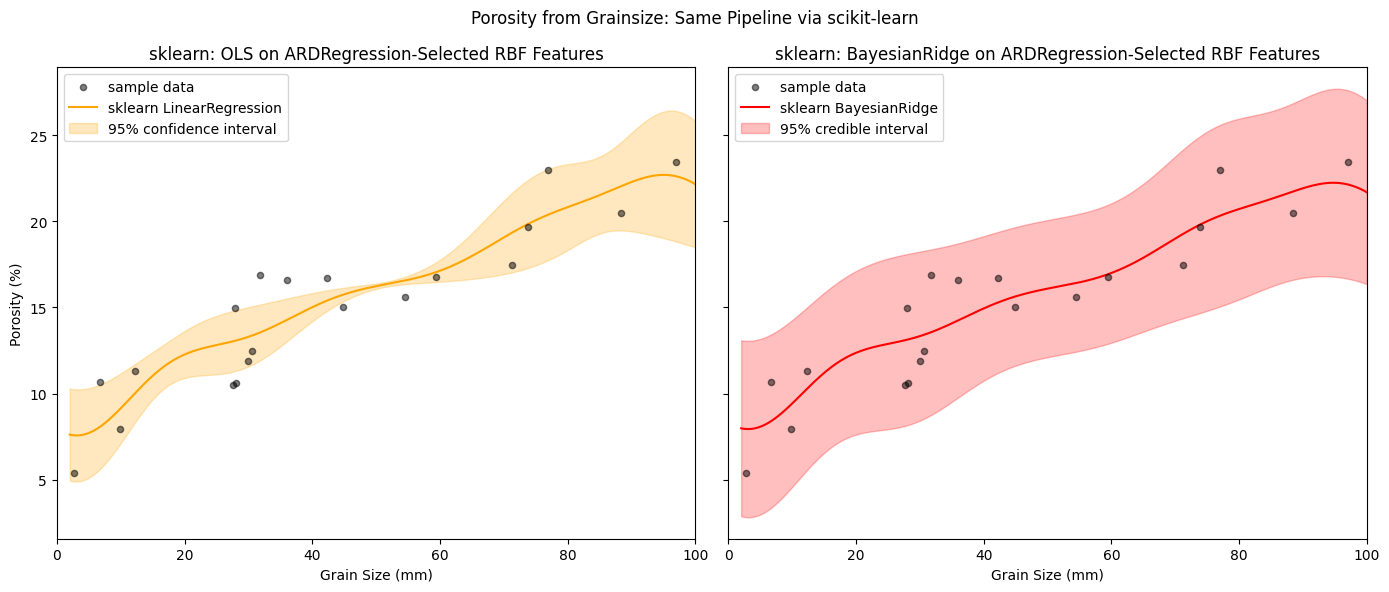

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axs[0].scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
axs[0].plot(grid_sk, y_lr_sk, color='orange', label='sklearn LinearRegression', zorder=2)
axs[0].fill_between(grid_sk, lr_sk_lower, lr_sk_upper, color='orange', alpha=0.25,
                     label='95% confidence interval')
axs[0].set_title('sklearn: OLS on ARDRegression-Selected RBF Features')
axs[0].set_xlabel('Grain Size (mm)'); axs[0].set_ylabel('Porosity (%)')
axs[0].set_xlim(0, 100)
axs[0].legend()

axs[1].scatter(X_data, y_data, color='black', s=20, alpha=0.5, label='sample data', zorder=3)
axs[1].plot(grid_sk, y_br_sk_mean, color='red', label='sklearn BayesianRidge', zorder=2)
axs[1].fill_between(grid_sk, y_br_sk_mean - 1.96 * y_br_sk_std, y_br_sk_mean + 1.96 * y_br_sk_std,
                     color='red', alpha=0.25, label='95% credible interval')
axs[1].set_title('sklearn: BayesianRidge on ARDRegression-Selected RBF Features')
axs[1].set_xlabel('Grain Size (mm)')
axs[1].set_xlim(0, 100)
axs[1].legend()

plt.suptitle('Porosity from Grainsize: Same Pipeline via scikit-learn')
plt.tight_layout()
plt.show()

Same shape of result as the from-scratch version: `ARDRegression` prunes the RBF basis down to a compact, well-separated set of relevant centers, and `LinearRegression`/`BayesianRidge` on that reduced feature set reproduce the same wiggly-but-sensible fit with wider uncertainty away from the data. The main practical difference is `BayesianRidge`'s single shared prior precision (`alpha`) across all weights, versus each weight keeping its own ARD precision in the hand-rolled version above — which is why scikit-learn's `ARDRegression` itself (fit directly on the full basis, no separate refit step) is often the more natural one-call choice when the goal is both selection *and* the final fit.